**ANALYZING STUDENTS' MENTAL HEALTH**

![Illustration of silhouetted heads](mentalhealth.jpg)

## 1. Research Question and Objectives

**Research Question**

How is the length of stay in Japan associated with depression, social connectedness, and acculturative stress among international university students?

**Research Objectives**

- Examine differences in average depression scores (PHQ-9) across lengths of stay.

- Assess how average social connectedness (SCS) varies with length of stay.

- Investigate differences in average acculturative stress (ASISS) across lengths of stay.

- Identify observable patterns and assess their reliability in relation to sample sizes.

**Analytical Approach**

The analysis uses descriptive statistics to explore potential associations between length of stay and the three mental health indicators. It does not attempt to establish causality or statistical significance.

## 2. Methodology

**Data Source and Study Population**

The analysis uses a dataset from a 2018 survey conducted at an international university in Japan, subsequently discussed in a published study. The dataset contains 286 student records, including 201 international students. The analysis focuses exclusively on international students to explore potential associations between their length of stay in Japan and mental health indicators.

**Variables**

The following variables were selected:

| Variable        |  Description                                    | Role                 |
| -------------   | ----------------------------------------------  | -------------------  |
| stay            | Length of stay in Japan, measured in years      | Explanatory variable |
| todep           | Depression score (PHQ-9)                        | Outcome variable     |
| tosc            | Social connectedness score (SCS)                | Outcome variable     |
| toas            | Acculturative stress score (ASISS)              | Outcome variable     | 
| inter_dom       | Types of students (international or domestic)   | Population filter    |

**Analytical Methods**

The project uses exploratory descriptive analysis, combining PostgreSQL and Python.

The methodology consists of:

- Data exploration: Examining the dataset structure, variables, and student population.

- Data validation: Assessing data completeness for the selected variables.

- SQL aggregation: Grouping international students by length of stay and calculating sample sizes and average mental   health scores.

- Data visualization: Using Python and Matplotlib to examine differences in average scores across length-of-stay groups.

- Interpretation: Evaluating observed patterns while considering sample size and methodological limitations.

The main visualizations focus on students with 1–4 years of stay, representing 194 of the 201 international students. Longer-stay groups are retained in the sample-size overview but excluded from the main trend charts because of their limited observations.

**Scope of the Analysis**

This is an observational, cross-sectional, descriptive analysis. It examines differences between student groups rather than changes in the same individuals over time. No inferential statistical tests or causal models are applied. Consequently, the results are interpreted as exploratory associations rather than evidence of statistical significance or causation.

## 3. Dataset Exploration

**Examine the dataset structure**

In [133]:
SELECT *
FROM students
LIMIT 10;

,inter_dom,region,gender,academic,age,age_cate,stay,stay_cate,japanese,japanese_cate,english,english_cate,intimate,religion,suicide,dep,deptype,todep,depsev,tosc,apd,ahome,aph,afear,acs,aguilt,amiscell,toas,partner,friends,parents,relative,profess,phone,doctor,reli,alone,others,internet,partner_bi,friends_bi,parents_bi,relative_bi,professional_bi,phone_bi,doctor_bi,religion_bi,alone_bi,others_bi,internet_bi
0,Inter,SEA,Male,Grad,24,4,5,Long,3,Average,5,High,,Yes,No,No,No,0,Min,34,23,9,11,8,11,2,27,91,5,5,6,3,2,1,4,1,3,4,NaN,Yes,Yes,Yes,No,No,No,No,No,No,No,No
1,Inter,SEA,Male,Grad,28,5,1,Short,4,High,4,High,,No,No,No,No,2,Min,48,8,7,5,4,3,2,10,39,7,7,7,4,4,4,4,1,1,1,NaN,Yes,Yes,Yes,No,No,No,No,No,No,No,No
2,Inter,SEA,Male,Grad,25,4,6,Long,4,High,4,High,Yes,Yes,No,No,No,2,Min,41,13,4,7,6,4,3,14,51,3,3,3,1,1,2,1,1,1,1,NaN,No,No,No,No,No,No,No,No,No,No,No
3,Inter,EA,Female,Grad,29,5,1,Short,2,Low,3,Average,No,No,No,No,No,3,Min,37,16,10,10,8,6,4,21,75,5,5,5,5,5,2,2,2,4,4,NaN,Yes,Yes,Yes,Yes,Yes,No,No,No,No,No,No
4,Inter,EA,Female,Grad,28,5,1,Short,1,Low,3,Average,Yes,No,No,No,No,3,Min,37,15,12,5,8,7,4,31,82,5,5,5,2,5,2,5,5,4,4,NaN,Yes,Yes,Yes,No,Yes,No,Yes,Yes,No,No,No
5,Inter,SEA,Male,Grad,24,4,6,Long,3,Average,4,High,Yes,No,No,No,No,6,Mild,38,18,8,10,8,7,3,29,83,6,5,4,2,1,1,2,1,5,1,NaN,Yes,Yes,No,No,No,No,No,No,Yes,No,No
6,Inter,SA,Male,Grad,23,4,1,Short,3,Average,5,High,Yes,No,No,No,No,3,Min,46,17,6,10,5,3,2,15,58,7,5,7,2,2,1,5,1,1,1,NaN,Yes,Yes,Yes,No,No,No,Yes,No,No,No,No
7,Inter,SEA,Female,Grad,30,5,2,Medium,1,Low,1,Low,Yes,Yes,Yes,No,No,9,Mild,41,16,20,19,15,11,6,40,127,7,2,2,2,6,2,1,1,3,1,NaN,Yes,No,No,No,Yes,No,No,No,No,No,No
8,Inter,SEA,Female,Grad,25,4,4,Long,4,High,4,High,No,No,No,Yes,Other,7,Mild,36,22,12,13,13,10,6,33,109,4,4,4,4,4,4,4,4,4,4,NaN,No,No,No,No,No,No,No,No,No,No,No
9,Inter,Others,Male,Grad,31,5,2,Medium,1,Low,4,High,Yes,Yes,No,No,No,3,Min,48,8,4,5,12,3,2,17,51,1,1,1,2,1,1,2,1,2,1,NaN,No,No,No,No,No,No,No,No,No,No,No


**Identify variables and data types**

In [134]:
SELECT
    column_name,
    data_type
FROM information_schema.columns
WHERE table_name = 'students'
ORDER BY ordinal_position;

,column_name,data_type
0,inter_dom,text
1,region,text
2,gender,text
3,academic,text
4,age,integer
5,age_cate,integer
6,stay,integer
7,stay_cate,text
8,japanese,integer
9,japanese_cate,text


**Display the total number of observations**

In [135]:
SELECT
    COUNT(*) AS total_students
FROM students;

,total_students
0,286


**Examine the student population distribution**

In [136]:
SELECT
    inter_dom,
    COUNT(*) AS student_count,
    ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS percentage
FROM students
GROUP BY inter_dom
ORDER BY student_count DESC;

,inter_dom,student_count,percentage
0,Inter,201,70.28
1,Dom,67,23.43
2,,18,6.29


**Examine the length-of-stay distribution**

In [137]:
SELECT
    stay,
    COUNT(*) AS student_count
FROM students
WHERE inter_dom = 'Inter'
GROUP BY stay
ORDER BY stay ASC;

,stay,student_count
0,1,95
1,2,39
2,3,46
3,4,14
4,5,1
5,6,3
6,7,1
7,8,1
8,10,1


**Descriptive variable analysis**

In [138]:
SELECT
    MIN(stay) AS min_stay,
    MAX(stay) AS max_stay,
    ROUND(AVG(stay), 2) AS avg_stay,

    MIN(todep) AS min_phq,
    MAX(todep) AS max_phq,
    ROUND(AVG(todep), 2) AS avg_phq,

    MIN(tosc) AS min_scs,
    MAX(tosc) AS max_scs,
    ROUND(AVG(tosc), 2) AS avg_scs,

    MIN(toas) AS min_asiss,
    MAX(toas) AS max_asiss,
    ROUND(AVG(toas), 2) AS avg_asiss
FROM students
WHERE inter_dom = 'Inter';

,min_stay,max_stay,avg_stay,min_phq,max_phq,avg_phq,min_scs,max_scs,avg_scs,min_asiss,max_asiss,avg_asiss
0,1,10,2.06,0,25,8.04,11,48,37.42,36,145,75.56


**Dataset Exploration — Summary**

The dataset contains 286 student records and 50 variables, covering student characteristics and mental health indicators. Of the 286 students, 201 (70.28%) are international students, 67 (23.43%) are domestic students, and 18 (6.29%) with an unspecified classification.

The analysis focuses on international students, examining length of stay in Japan and three mental health measures: depression (PHQ-9), social connectedness (SCS), and acculturative stress (ASISS). The length-of-stay distribution is uneven, with 194 of the 201 international students (96.52%) having stayed between one and four years. The remaining seven students have stayed five years or longer.

Descriptive statistics are used to examine the ranges and average values of the selected analytical variables. The resulting distributions and sample sizes inform the subsequent analysis and interpretation.

## 4. Data Completeness Validation

**Check missing values in the analytical variables**

In [139]:
SELECT
    COUNT(*) AS total_students,
	COUNT(stay) AS valid_stay,
    COUNT(todep) AS valid_phq,
    COUNT(tosc) AS valid_scs,
    COUNT(toas) AS valid_as
FROM students
WHERE inter_dom = 'Inter';

,total_students,valid_stay,valid_phq,valid_scs,valid_as
0,201,201,201,201,201


**Calculate the number of missing values**

In [140]:
SELECT
    COUNT(*) - COUNT(stay) AS missing_stay,
    COUNT(*) - COUNT(todep) AS missing_phq,
    COUNT(*) - COUNT(tosc) AS missing_scs,
    COUNT(*) - COUNT(toas) AS missing_asiss
FROM students
WHERE inter_dom = 'Inter';

,missing_stay,missing_phq,missing_scs,missing_asiss
0,0,0,0,0


**Calculate the percentage of missing values**

In [141]:
SELECT
    ROUND(100.0 * (COUNT(*) - COUNT(stay)) / COUNT(*), 2) AS pct_missing_stay,

    ROUND(100.0 * (COUNT(*) - COUNT(todep)) / COUNT(*), 2) AS pct_missing_phq,

    ROUND(100.0 * (COUNT(*) - COUNT(tosc)) / COUNT(*), 2) AS pct_missing_scs,

    ROUND(100.0 * (COUNT(*) - COUNT(toas)) / COUNT(*), 2) AS pct_missing_asiss
FROM students
WHERE inter_dom = 'Inter';

,pct_missing_stay,pct_missing_phq,pct_missing_scs,pct_missing_asiss
0,0.0,0.0,0.0,0.0


**Examine completeness by length of stay**

In [142]:
SELECT
    stay,
    COUNT(*) AS total_students,
    COUNT(todep) AS valid_phq,
    COUNT(tosc) AS valid_scs,
    COUNT(toas) AS valid_asiss
FROM students
WHERE inter_dom = 'Inter'
GROUP BY stay
ORDER BY stay ASC;

,stay,total_students,valid_phq,valid_scs,valid_asiss
0,1,95,95,95,95
1,2,39,39,39,39
2,3,46,46,46,46
3,4,14,14,14,14
4,5,1,1,1,1
5,6,3,3,3,3
6,7,1,1,1,1
7,8,1,1,1,1
8,10,1,1,1,1


**Data Completeness Validation — Summary**

| Variable | Valid observations | Missing values | Missing (%) |
|---|---:|---:|---:|
| Length of stay | 201 | 0 | 0.00% |
| Depression (PHQ-9) | 201 | 0 | 0.00% |
| Social connectedness (SCS) | 201 | 0 | 0.00% |
| Acculturative stress (ASISS) | 201 | 0 | 0.00% |

All 201 international students had non-missing observations for length of stay, depression (PHQ-9), social connectedness (SCS), and acculturative stress (ASISS). The missing-value rate was 0.00% for each variable. Therefore, all 201 international students were retained for the subsequent descriptive analysis. These results confirm completeness for the selected analytical variables but do not establish the accuracy or validity of individual survey responses.

## 5. SQL Aggregation

**Average mental health scores by length of stay**

In [143]:
SELECT
    stay,
    COUNT(*) AS count_int,
    ROUND(AVG(todep), 2) AS average_phq,
    ROUND(AVG(tosc), 2) AS average_scs,
    ROUND(AVG(toas), 2) AS average_as
FROM students
WHERE inter_dom = 'Inter'
GROUP BY stay
ORDER BY stay ASC;

,stay,count_int,average_phq,average_scs,average_as
0,1,95,7.48,38.11,72.80
1,2,39,8.28,37.08,77.67
2,3,46,9.09,37.13,78.00
3,4,14,8.57,33.93,87.71
4,5,1,0.00,34.00,91.00
5,6,3,6.00,38.00,58.67
6,7,1,4.00,48.00,45.00
7,8,1,10.00,44.00,65.00
8,10,1,13.00,32.00,50.00


**Verify the aggregated results in Python (Dataframe = df)**

In [144]:
print(df.head(9))
print(df.dtypes)

   stay  count_int  average_phq  average_scs  average_as
0     1         95         7.48        38.11       72.80
1     2         39         8.28        37.08       77.67
2     3         46         9.09        37.13       78.00
3     4         14         8.57        33.93       87.71
4     5          1         0.00        34.00       91.00
5     6          3         6.00        38.00       58.67
6     7          1         4.00        48.00       45.00
7     8          1        10.00        44.00       65.00
8    10          1        13.00        32.00       50.00
stay             int64
count_int        int64
average_phq    float64
average_scs    float64
average_as     float64
dtype: object


**Verify the total sample size**

In [145]:
print("Total students:", df["count_int"].sum())
print("Length-of-stay groups:", len(df))

Total students: 201
Length-of-stay groups: 9


**Sample sizes for years 1–4 and over**

In [146]:
print("Students staying 1–4 years:", 
    df.loc[df["stay"].between(1, 4), "count_int"].sum())

print("Students staying over 4 years:",
    df.loc[df["stay"] > 4, "count_int"].sum())

Students staying 1–4 years: 194
Students staying over 4 years: 7


**SQL Aggregation — Summary**

PostgreSQL was used to group the 201 international students by their length of stay in Japan. For each group, the following statistics were calculated:

- Number of students (COUNT)
- Average depression score — PHQ-9 (AVG)
- Average social connectedness score — SCS (AVG)
- Average acculturative stress score — ASISS (AVG)

The analysis identified nine length-of-stay groups.

Of the 201 international students, 194 (96.52%) had stayed between one and four years, while only seven (3.48%) had stayed longer than four years. Because the longer-stay groups contain very few students, the primary visualizations will focus on years 1–4. All nine groups will remain represented in the sample-size visualization.The aggregated results provide the foundation for examining descriptive differences in mental health indicators across length-of-stay groups.

## 6. Depression (PHQ-9) Visualization

**Import the required Python libraries**

In [147]:
import pandas as pd
import matplotlib.pyplot as plt

**Filter the DataFrame (df) for stays of 1–4 years**

In [148]:
df_filtered = df[(df["stay"] >= 1) & (df["stay"] <= 4)].sort_values("stay")
print(df_filtered)

   stay  count_int  average_phq  average_scs  average_as
0     1         95         7.48        38.11       72.80
1     2         39         8.28        37.08       77.67
2     3         46         9.09        37.13       78.00
3     4         14         8.57        33.93       87.71


**Create the depression visualization**

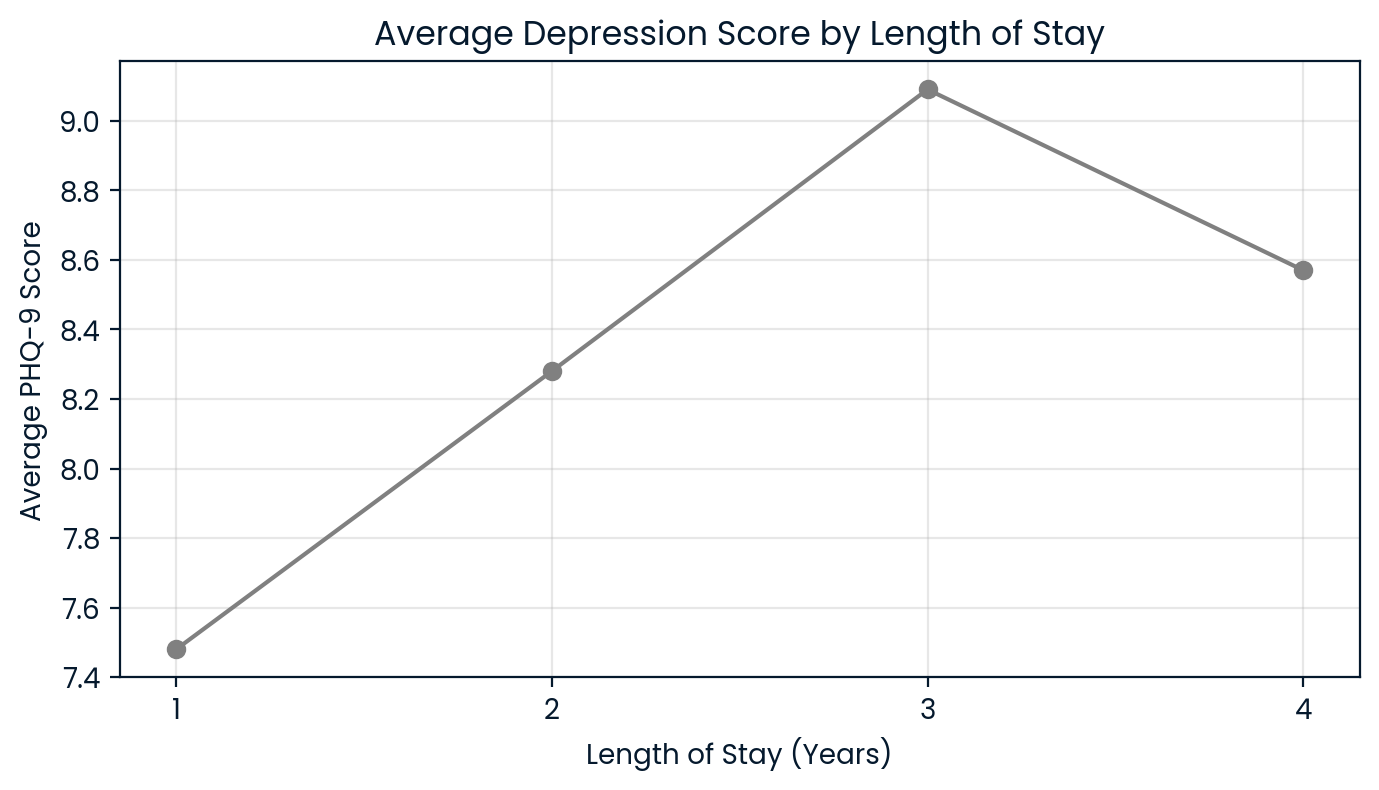

In [149]:
plt.figure(figsize=(8, 4))

plt.plot(
    df_filtered["stay"],
    df_filtered["average_phq"],
    marker="o",
    color="gray"
)

plt.title("Average Depression Score by Length of Stay")
plt.xlabel("Length of Stay (Years)")
plt.ylabel("Average PHQ-9 Score")

plt.xticks([1, 2, 3, 4])
plt.grid(alpha=0.3)

plt.show()

**Depression (PHQ-9) Visualization — Summary**

| Length of Stay (Years) | Average PHQ-9 Score |
|---|---:|
| 1 | 7.48 |
| 2 | 8.28 |
| 3 | 9.09 |
| 4 | 8.57 |

Average depression scores were examined across international students with lengths of stay ranging from one to four years.

The average PHQ-9 score increased from 7.48 in the first-year group to 8.28 in the second-year group and 9.09 in the third-year group, before declining to 8.57 in the fourth-year group. The highest average depression score was observed among students who had stayed for three years.

Although the results indicate differences in average depression scores across groups, they do not demonstrate a consistently increasing relationship between length of stay and depression. These findings are descriptive and do not establish statistical significance or causality.

## 7. Social Connectedness (SCS) Visualization

**Prepare the data**

In [150]:
print(df_filtered[["stay", "average_scs"]])

   stay  average_scs
0     1        38.11
1     2        37.08
2     3        37.13
3     4        33.93


**Create the social connectedness visualization**

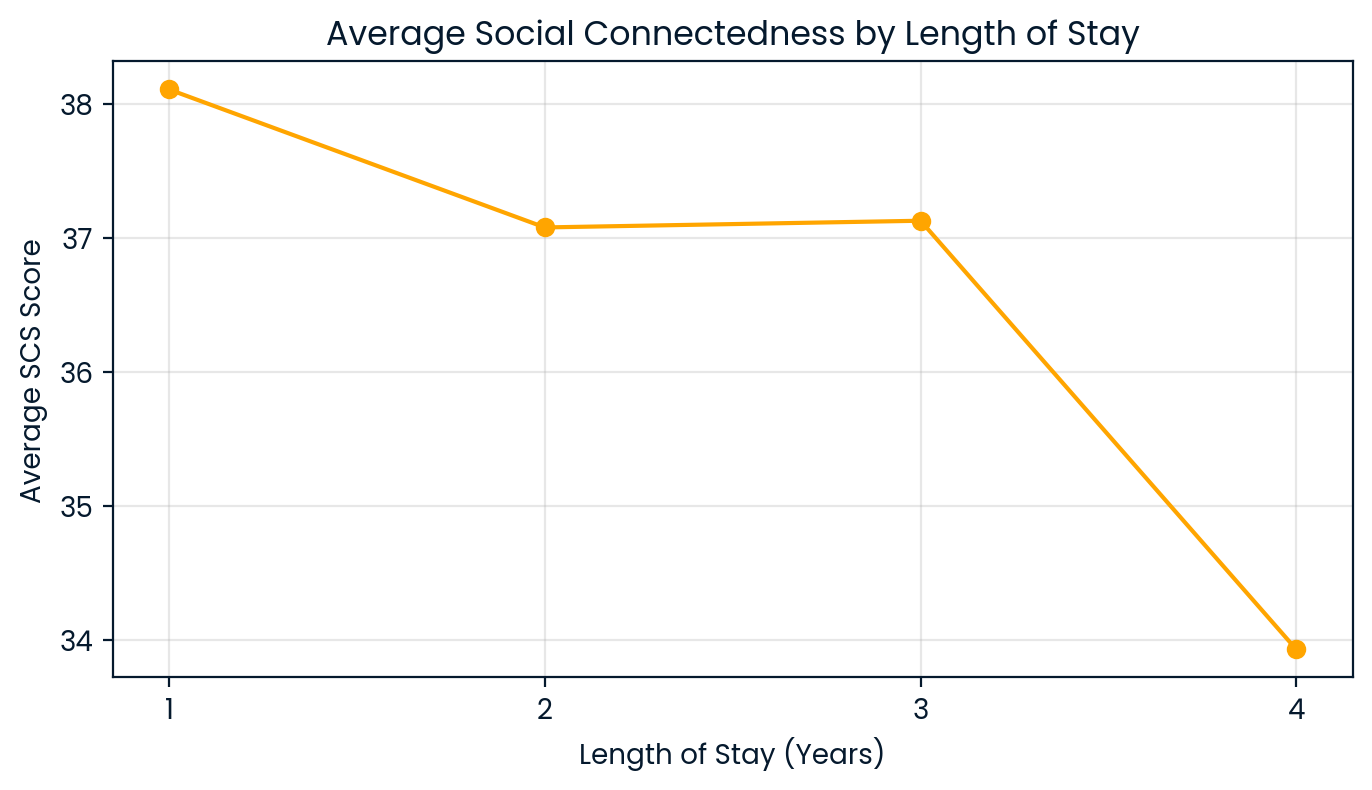

In [151]:
plt.figure(figsize=(8, 4))

plt.plot(
    df_filtered["stay"],
    df_filtered["average_scs"],
    marker="o",
    color="orange"
)

plt.title("Average Social Connectedness by Length of Stay")
plt.xlabel("Length of Stay (Years)")
plt.ylabel("Average SCS Score")

plt.xticks([1, 2, 3, 4])
plt.grid(alpha=0.3)

plt.show()

**Social Connectedness (SCS) Visualization — Summary**

| Length of Stay (Years) | Average SCS Score |
|---|---:|
| 1 | 38.11 |
| 2 | 37.08 |
| 3 | 37.13 |
| 4 | 33.93 |

Average social connectedness scores were examined among international students with lengths of stay ranging from one to four years.

The average SCS score decreased from 38.11 in the first-year group to 37.08 in the second-year group, followed by a slight increase to 37.13 in the third-year group. The lowest average score of 33.93 was observed in the fourth-year group. Overall, social connectedness decreased by 4.18 points between the first-year and fourth-year groups, representing an approximately 10.97% reduction.

Although the findings suggest generally lower social connectedness among students with longer stays, the slight increase between the second and third years indicates that the pattern is not consistently downward. These findings are descriptive and do not establish statistical significance or a causal relationship between length of stay and social connectedness.

## 8. Acculturative Stress (ASISS) Visualization

**Prepare the data**

In [152]:
print(df_filtered[["stay", "average_as"]])

   stay  average_as
0     1       72.80
1     2       77.67
2     3       78.00
3     4       87.71


**Create the acculturative stress visualization**

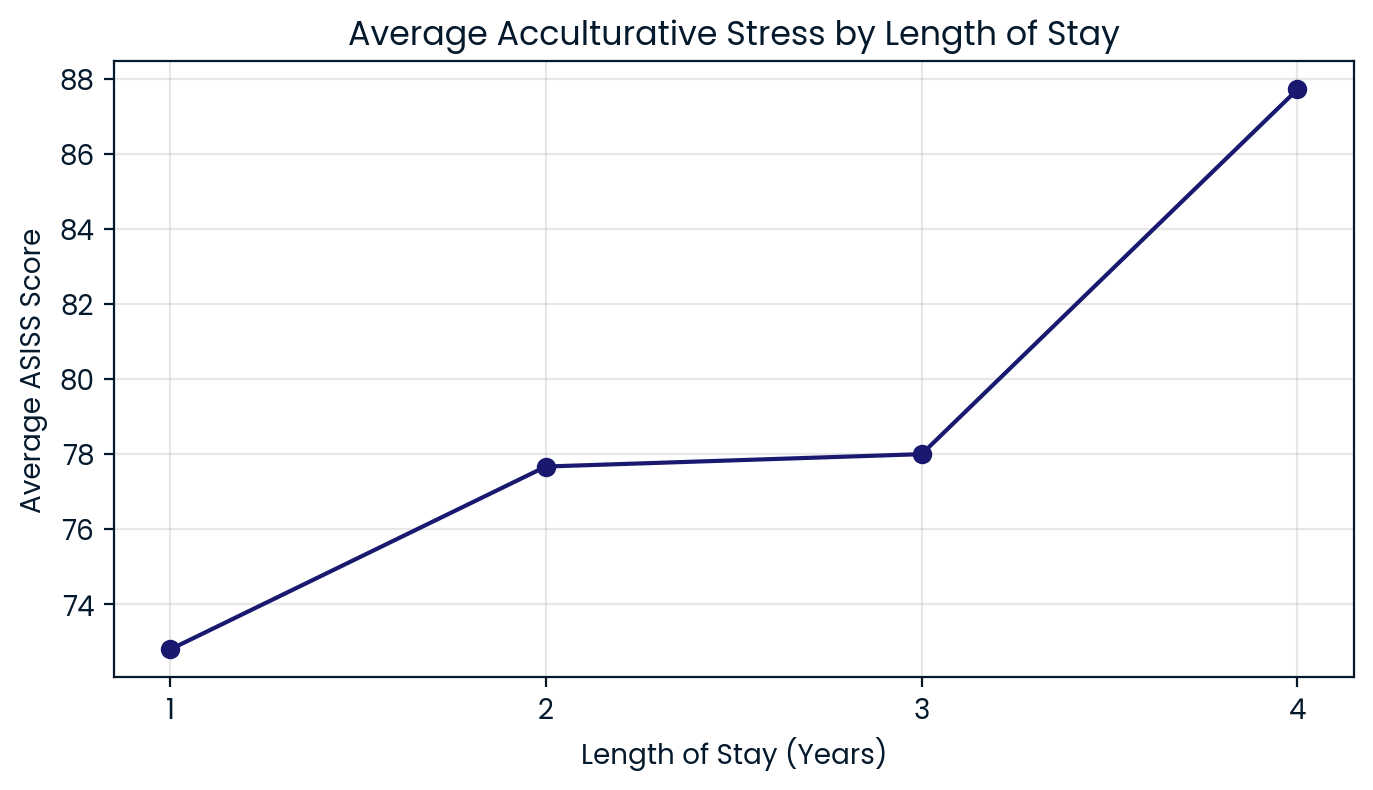

In [153]:
plt.figure(figsize=(8, 4))

plt.plot(
    df_filtered["stay"],
    df_filtered["average_as"],
    marker="o",
    color="midnightblue"
)

plt.title("Average Acculturative Stress by Length of Stay")
plt.xlabel("Length of Stay (Years)")
plt.ylabel("Average ASISS Score")

plt.xticks([1, 2, 3, 4])
plt.grid(alpha=0.3)

plt.show()

**Acculturative Stress (ASISS) Visualization — Summary**

| Length of Stay (Years) | Average ASISS Score |
|---|---:|
| 1 | 72.80 |
| 2 | 77.67 |
| 3 | 78.00 |
| 4 | 87.71 |

Average acculturative stress scores were examined among international students with lengths of stay ranging from one to four years.

The average ASISS score increased from 72.80 in the first-year group to 77.67 in the second-year group, followed by a slight increase to 78.00 in the third-year group. The highest average score of 87.71 was observed in the fourth-year group. Overall, acculturative stress increased by 14.91 points between the first-year and fourth-year groups, representing an approximately 20.48% increase.

The findings indicate a consistently increasing pattern of average acculturative stress across the four length-of-stay groups. The largest increase occurred between the third and fourth years (9.71 points). These results suggest that students with longer stays tend to report higher average acculturative stress scores. However, the findings are descriptive and do not establish statistical significance or a causal relationship between length of stay and acculturative stress.

## 9. Sample-Size Visualization

**Prepare the data**

In [154]:
print(df[["stay", "count_int"]].sort_values("stay"))

   stay  count_int
0     1         95
1     2         39
2     3         46
3     4         14
4     5          1
5     6          3
6     7          1
7     8          1
8    10          1


**Create the sample-size visualization**

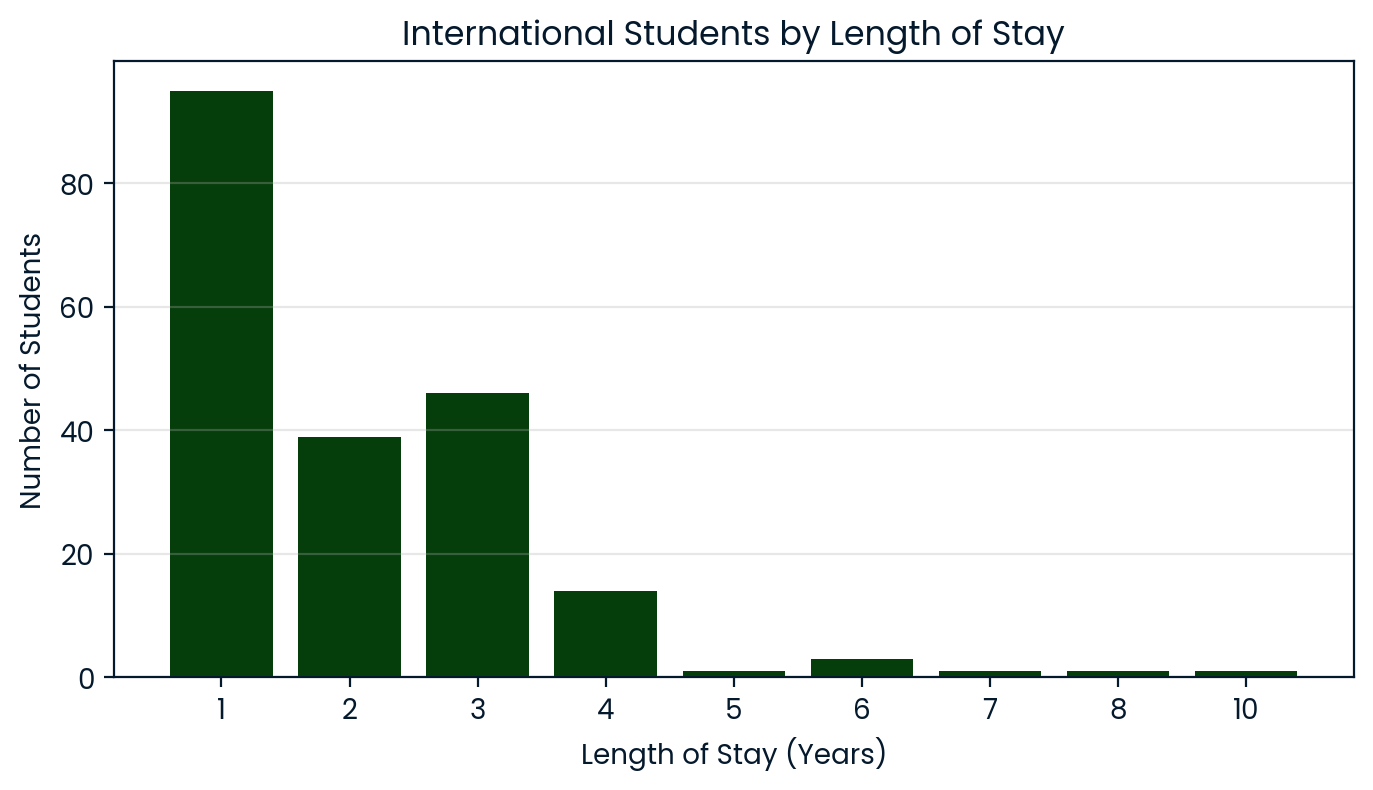

In [155]:
plt.figure(figsize=(8, 4))

plt.bar(
    df["stay"].astype(str),
    df["count_int"],
    color='#053d0b'
)

plt.title("International Students by Length of Stay")
plt.xlabel("Length of Stay (Years)")
plt.ylabel("Number of Students")

plt.grid(axis="y", alpha=0.3)
plt.show()

**Sample-Size Visualization — Summary**

| Length of Stay (Years) | Number of Students |
|---|---:|
| 1 | 95 |
| 2 | 39 |
| 3 | 46 |
| 4 | 14 |
| 5 | 1 |
| 6 | 3 |
| 7 | 1 |
| 8 | 1 |
| 10 | 1 |
| **Total** | **201** |

The distribution of international students across lengths of stay is highly uneven. Of the 201 international students, 194 (96.52%) had stayed in Japan for one to four years, while only seven (3.48%) had stayed for five years or longer. The largest group consists of first-year students (95), followed by third-year students (46), second-year students (39), and fourth-year students (14). The remaining length-of-stay groups contain between one and three students each. Such small sample sizes make their group averages particularly sensitive to individual observations.

Consequently, the primary mental health visualizations focus on students with lengths of stay between one and four years. All nine groups are retained in the sample-size visualization to provide a complete overview of the study population. Although the first four groups contain most international students, their unequal sample sizes should also be considered when interpreting differences in average mental health scores.

## 10. Results and Interpretation

### Research Question

- How is the length of stay in Japan associated with depression, social connectedness, and acculturative stress among international university students?

The analysis focuses on the 194 international students who had stayed in Japan for one to four years, representing 96.52% of the 201 international students in the dataset.

### Summary of Mental Health Indicators

| Length of Stay (Years) | Students | Average PHQ-9 | Average SCS | Average ASISS |
|---|---:|---:|---:|---:|
| 1 | 95 | 7.48 | 38.11 | 72.80 |
| 2 | 39 | 8.28 | 37.08 | 77.67 |
| 3 | 46 | 9.09 | 37.13 | 78.00 |
| 4 | 14 | 8.57 | 33.93 | 87.71 |
| **Total** | **194** | — | — | — |

The results represent group-level averages calculated using PostgreSQL. Overall mean scores are not displayed in the total row because they would require weighting by group sample size.

### Depression (PHQ-9)

Average depression scores increased from 7.48 in the first-year group to 8.28 in the second-year group, reaching their highest value of 9.09 in the third-year group. The average subsequently declined to 8.57 in the fourth-year group. The difference between the first-year and fourth-year groups was 1.09 points, representing approximately 14.57% higher average depression scores in the fourth-year group.

Although depression scores were higher in all three later groups compared with the first-year group, the pattern was not consistently increasing. These findings suggest descriptive differences in depression scores across lengths of stay, without establishing a statistically significant association.

### Social Connectedness (SCS)

Average social connectedness declined from 38.11 in the first-year group to 37.08 in the second-year group, followed by a slight increase to 37.13 in the third-year group. The lowest average score of 33.93 was observed in the fourth-year group. The difference between the first-year and fourth-year groups was 4.18 points, representing an approximately 10.97% reduction.

Overall, the results suggest lower average social connectedness among students in longer-stay groups. However, the slight increase between the second and third years indicates that the pattern was not consistently downward.

### Acculturative Stress (ASISS)

Average acculturative stress increased consistently across the four groups. The average ASISS score increased from 72.80 in the first-year group to 77.67 in the second-year group and 78.00 in the third-year group, reaching its highest value of 87.71 in the fourth-year group. 

The difference between the first-year and fourth-year groups was 14.91 points, representing an approximately 20.48% increase. The largest increase occurred between the third and fourth years, when the average ASISS score rose by 9.71 points. Among the three indicators examined, acculturative stress demonstrated the clearest consistently increasing pattern across the four length-of-stay groups.

### Combined Interpretation

The combined results reveal three descriptive patterns:

1. **Depression:** Average PHQ-9 scores were higher in the second-, third-, and fourth-year groups than in the first-year group, although the pattern was not consistently increasing.

2. **Social Connectedness:** Average SCS scores generally decreased across length-of-stay groups, with the lowest average observed among fourth-year students.

3. **Acculturative Stress:** Average ASISS scores increased consistently across all four groups, with the highest average observed among fourth-year students.

Altogether, these results suggest that longer lengths of stay are associated descriptively with higher acculturative stress and generally lower social connectedness. The depression results are less consistent but show higher average scores among students in the later groups compared with first-year students.

These findings are broadly compatible with the original study's emphasis on depression, social connectedness, and acculturative stress. However, the present analysis does not directly examine the statistical relationships between the three mental health measures. Consequently, it cannot establish whether social connectedness or acculturative stress predicts depression.

### Sample-Size Considerations

The distribution of international students across lengths of stay was highly uneven. Of the 201 international students, 194 (96.52%) had stayed for one to four years, while only seven (3.48%) had stayed for five years or longer. Groups with stays exceeding four years contained between one and three students each and were therefore excluded from the primary trend visualizations.

Within the primary analysis, the sample sizes ranged from 95 first-year students to only 14 fourth-year students. The particularly small fourth-year group means that its average scores may be more sensitive to individual observations.  The unequal sample sizes should be considered when interpreting differences between the four groups.

### Answer to the Research Question

The exploratory analysis identified differences in depression, social connectedness, and acculturative stress across length-of-stay groups among international university students in Japan. Acculturative stress exhibited a consistently increasing pattern, while social connectedness generally declined across the first four years. Depression scores fluctuated but remained higher in the second-, third-, and fourth-year groups than in the first-year group.

**These results suggest potential associations between length of stay and the examined mental health indicators. However, the analysis is descriptive and cross-sectional. It does not establish statistical significance, quantify the strength of the associations, or support causal conclusions. Further inferential analysis, including consideration of potential confounding variables, would be necessary to evaluate these relationships more rigorously.**

## 11. Limitations and Recommendations for Future Research

**Unequal Sample Sizes**

The distribution of international students across lengths of stay was highly uneven. Of the 201 international students, 194 (96.52%) had stayed in Japan for one to four years, while only seven (3.48%) had stayed for five years or longer. The groups representing stays of five years or longer contained only one to three students each and were excluded from the primary trend visualizations.

Within the primary analysis, group sizes ranged from 95 students in the first-year group to 14 students in the fourth-year group. The unequal sample sizes may affect the stability and comparability of group averages. In particular, the fourth-year group's relatively small sample makes its average scores more sensitive to individual observations.

**Cross-Sectional Study Design**

The dataset represents observations collected through a student survey rather than repeated measurements of the same individuals over time. Consequently, differences between length-of-stay groups should not be interpreted as evidence that individual students experience changes in mental health as their stay in Japan progresses. **A longitudinal study would be better suited to examining changes in mental health over time.**

**Potential Confounding Variables**

The analysis examines associations between length of stay and mental health indicators without controlling for other potentially relevant factors. Possible confounding variables include:

- Age
- Gender
- Academic level
- Japanese language proficiency
- Social support
- Individual circumstances

These factors may influence both length of stay and mental health outcomes. Without accounting for potential confounders, the observed differences cannot be attributed solely to length of stay.

**Descriptive Analysis Without Statistical Testing**

The analysis relies on group-level averages calculated using PostgreSQL. No inferential statistical tests, confidence intervals, or regression models were applied. **Therefore, the analysis cannot establish whether the observed differences are statistically significant or distinguishable from sampling variation**.

**Generalizability**

The dataset originates from a survey conducted at a single international university in Japan. The participants may not be representative of international students attending other universities or studying in different countries. Consequently, the findings should not be generalized to all international university students without further evidence.

**Association Versus Causation**

Although the analysis identified higher average acculturative stress and generally lower social connectedness among students in longer-stay groups, these descriptive patterns do not establish causal relationships. Furthermore, the analysis did not directly test the relationships between depression, social connectedness, and acculturative stress.


**Despite the aforementioned limitations**, the analysis provides a structured exploratory examination of mental health indicators among international university students. The combination of SQL aggregation, data completeness checks, and Python visualizations supports transparent examination of the observed patterns. However, the findings remain descriptive and should be interpreted cautiously. Further research incorporating larger and more balanced samples, inferential statistical methods, and adjustment for potential confounding variables would be necessary to evaluate the associations more rigorously.

## 12. Conclusions

The project investigated the association between length of stay in Japan and three mental health indicators — depression (PHQ-9), social connectedness (SCS), and acculturative stress (ASISS) — among international university students. The dataset contained 286 student records, including 201 international students. Data completeness validation confirmed that all 201 international students had non-missing observations for the four analytical variables. The primary analysis focused on 194 students with lengths of stay between one and four years.

The descriptive findings suggest that international students in longer-stay groups generally exhibit higher average acculturative stress and lower average social connectedness. Depression scores also differ across length-of-stay groups, although the observed pattern is less consistent. These findings are broadly compatible with the original study's emphasis on the importance of social connectedness and acculturative stress in international students' mental health. 

However, they should be interpreted cautiously because of the cross-sectional study design, unequal group sizes, and absence of inferential statistical testing. Moreover, the analysis does not establish statistically significant associations or causal relationships. In particular, differences between length-of-stay groups should not be interpreted as changes experienced by individual students over time. To address the above shortcomings of the study design, future research using larger and more balanced samples, longitudinal observations, and appropriate multivariable statistical methods could provide stronger evidence regarding these relationships.

Altogether, the project illustrates a reproducible analytical workflow for investigating health-related research questions by combining data validation, descriptive analysis, visualization, and critical interpretation. It also provides preliminary descriptive evidence of differences in mental health indicators across length-of-stay groups while recognizing the methodological limitations that prevent stronger conclusions.